#With document layout analysis

## Setup

###Dependencies

In [1]:
#DLA
%%capture
!pip install ultralytics

In [2]:
#OCR
%%capture
!pip install pytesseract
!sudo apt-get install tesseract-ocr
!apt-get install -y poppler-utils

In [3]:
#TTS
%%capture
!pip install gtts
!pip install pydub
!pip install pyrubberband resampy

In [4]:
%%capture
!sudo apt-get update -y
!sudo apt-get install -y rubberband-cli

In [ ]:
# %%capture
# !git clone https://github.com/VarunGumma/IndicTransTokenizer
# %cd IndicTransTokenizer

!pip install --editable ./
!pip install sacrebleu sacremoses indic-nlp-library

# %cd ..

#Restart session when prompted

###Importing libraries and loading models

In [1]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)
folder_path = '/content/drive/MyDrive/Final Year Project/dataset/RT-Dataset/fyp2'
%cd "$folder_path"

Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1e5DrQxsCmN1galay7ONG6gpAcYh0sdWc/2023-24-Final Year Project-Nishanth-Shrijith/dataset/RT-Dataset/fyp2


In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from PIL import Image,ImageDraw
import torch
from nltk import tokenize
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import pathlib

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [3]:
device = torch.device("cuda") if torch.cuda.is_available() else "cpu"

In [4]:
# #itm
%%capture
from transformers import AutoProcessor, Blip2ForImageTextRetrieval
itm_model = Blip2ForImageTextRetrieval.from_pretrained("Salesforce/blip2-itm-vit-g", torch_dtype=torch.float16)
itm_processor = AutoProcessor.from_pretrained("Salesforce/blip2-itm-vit-g")
itm_model.to(device)

In [5]:
#image captioning
from transformers import Blip2Processor, Blip2ForConditionalGeneration
import torch,accelerate

blip2_processor = Blip2Processor.from_pretrained("Salesforce/blip2-opt-2.7b")
blip2_model = Blip2ForConditionalGeneration.from_pretrained(
    "Salesforce/blip2-opt-2.7b", device_map="auto", torch_dtype=torch.bfloat16
)  # doctest: +IGNORE_RESULT

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/882 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (5 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/4.98G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/10.0G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

In [6]:
# document layout analysis model
from ultralytics import YOLO
# Load the document segmentation model
docseg_model = YOLO('yolov8x-doclaynet-epoch64-imgsz640-initiallr1e-4-finallr1e-5.pt')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [7]:
import pytesseract
pytesseract.pytesseract.tesseract_cmd = '/usr/bin/tesseract'

In [8]:
from gtts import gTTS
import pyrubberband as pyrb
import numpy as np
import tempfile
import soundfile as sf
from pydub import AudioSegment
from IPython.display import Audio
from io import BytesIO
import resampy

In [9]:
from transformers import AutoModelForSeq2SeqLM
from IndicTransTokenizer.IndicTransTokenizer import IndicProcessor, IndicTransTokenizer

trans_tokenizer = IndicTransTokenizer(direction="en-indic")
trans_model = AutoModelForSeq2SeqLM.from_pretrained("ai4bharat/indictrans2-en-indic-dist-200M", trust_remote_code=True)

config.json: 0.00B [00:00, ?B/s]

configuration_indictrans.py: 0.00B [00:00, ?B/s]

modeling_indictrans.py: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.10G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

In [10]:
trans_model = trans_model.to(device)

In [ ]:
# from transformers import CLIPProcessor, CLIPModel

# # Directory where your trained model is saved
# model_directory = "../clip-512-finetuned"

# # Load the processor and model
# clip_processor = CLIPProcessor.from_pretrained(model_directory)
# clip_model = CLIPModel.from_pretrained(model_directory).to(device)

##Document Layout Analysis

In [11]:
def calculate_iou(box1, box2):
    # box: [x1, y1, x2, y2]
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    return intersection / union if union != 0 else 0


In [31]:
def resolve_overlap(classes, iou_threshold=0.5):
    unique_boxes = []

    for class_name, items in classes.items():
        for box, score in items:
            keep = True
            for ub in unique_boxes:
                iou = calculate_iou(box, ub['box'])
                if iou > iou_threshold:
                    # Rule 1: Always keep caption if it's already there
                    if ub['class'] == 'Caption':
                        keep = False
                        break
                    # Rule 2: If current box is caption, replace any existing one
                    elif class_name == 'Caption':
                        ub['class'] = 'Caption'
                        ub['box'] = box
                        ub['score'] = score
                        keep = False
                        break
                    # Rule 3: Preference to Page-header over Page-footer
                    elif (ub['class'], class_name) in [('Page-footer', 'Page-header')]:
                        ub['class'] = 'Page-header'
                        ub['box'] = box
                        ub['score'] = score
                        keep = False
                        break
                    elif (ub['class'], class_name) in [('Page-header', 'Page-footer')]:
                        keep = False
                        break
                    # Rule 4: For other classes, keep the higher score
                    elif score > ub['score']:
                        ub['class'] = class_name
                        ub['box'] = box
                        ub['score'] = score
                        keep = False
                        break
                    else:
                        keep = False
                        break
            if keep:
                unique_boxes.append({'class': class_name, 'box': box, 'score': score})

    # Build cleaned-up dictionary
    new_classes = {}
    for item in unique_boxes:
        cls = item['class']
        if cls not in new_classes:
            new_classes[cls] = []
        new_classes[cls].append((item['box'], item['score']))

    return new_classes


In [13]:
# key for sorting
# old algo:
# def sort_key(item):
#     global image_path
#     img_width = Image.open(image_path).width
#     x_coordinate = item[0][0]
#     y_coordinate = item[0][1]

#     y_threshold = 5

#     x_column_threshold = img_width // 2

#     # Adjust y coordinate based on the column
#     if x_coordinate < x_column_threshold:
#         # Text is in the left column
#         y_coordinate_adjusted = y_coordinate // y_threshold * y_threshold
#     else:
#         # Text is in the right column
#         # Add an offset to differentiate from the left column
#         y_coordinate_adjusted = (y_coordinate // y_threshold * y_threshold) + 1000

#     return (y_coordinate_adjusted, x_coordinate)

def sort_key(item):
    x0, y0 = item[0][0], item[0][1]
    y_threshold = 10
    y_group = y0 // y_threshold
    return (y_group, x0)


#function for sorting bounding boxes
def sort_boxes(dla_info):

  for key,value in dla_info.items():
    dla_info[key] = sorted(value, key=sort_key)
  return dla_info


def dla(image_path):
  # List of sample images to process
  img_list = [image_path]
  # Process the images with the model
  results = docseg_model(source=img_list, save=True, show_labels=True, show_conf=True, show_boxes=True)

  # dictionary for each class
  dla_info = {}

  for result in results:
    path = pathlib.Path(result.path)
    classes = {}
    for box in result.boxes:
      box_data = box.data[0].cpu().numpy().tolist()
      bbox = box_data[:4]
      score = box_data[4]
      class_id = int(box_data[-1])
      class_name = docseg_model.names[class_id]
      bbox = [bbox[0] - 2, bbox[1] - 2, bbox[2] + 2, bbox[3] + 2 ]
      if class_name in classes:
        classes[class_name].append((bbox,score))
      else:
        classes[class_name] = [(bbox,score)]

    classes = resolve_overlap(classes)

    dla_info[path] = classes
    dla_info[path] = sort_boxes(dla_info[path])

  for path,box_data in dla_info.items():
    print('Image:',path)
    img = Image.open(path)

    # Create a copy to draw all boxes
    img_with_boxes = img.copy()
    draw = ImageDraw.Draw(img_with_boxes)

    # Draw boxes of all detected regions
    for key, value in box_data.items():
        for box, score in value:
            draw.rectangle(box, outline="red", width=1)
            draw.text((box[0]-20, box[1]-12), key, fill="red")

    # Show the whole page with all boxes first
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_boxes)
    plt.axis('off')
    plt.title("Full page with detected boxes")
    plt.show()
    img_with_boxes.save("/content/dla_output.png")

    for key,value in box_data.items():
      for box in value:
        print(key,box[0],box[1])
        cropped_img = img.crop((box[0][0],box[0][1],box[0][2],box[0][3]))
        plt.imshow(cropped_img)
        plt.axis('off')
        plt.show()
        print('----')

  info = [dla_info.copy(),{}]
  return info


info is in the form:

[
  {'path/to/pic':{'Text':[(bbox1,score1),(bbox2,score2)....],'Picture':[(bbox1,score1),(bbox2,score2),....],'Caption':[...],...}
  },

{'pic1':[caption,associated_text],'pic2':[],...}  
]


---

Classes: 11 classes (Caption, Footnote, Formula, List-item, Page-footer, Page-header, Picture, Section-header, Table, Text, and Title)

##OCR

In [14]:
def preprocess(cropped_image):
  # Convert the image to RGB mode (removes alpha channel)
  cropped_image = cropped_image.convert("RGB")

  width = cropped_image.width
  height = cropped_image.height

  # Resize the cropped image to a larger size using high-quality interpolation
  resize_factor = 4
  new_width = width * resize_factor
  new_height = height * resize_factor
  resized_image = cropped_image.resize((new_width, new_height), Image.BICUBIC)
  return resized_image

def textCleaner(text):
  # print('text:',text)
  filtered_text = [line.strip() for line in text.split("\n") if line.strip()]
  # print('filtered:',filtered_text)
  return " ".join(filtered_text)

def ocr():
  print("******************OCR**********************")
  texts_dict = {'compiled':[]}
  for key,value in info[0].items():
    image = Image.open(key)
    plt.imshow(image)
    plt.axis('off')
    plt.show()

    if 'Text' in value:
      texts = value['Text']
      #appending texts
      for i in texts:
        bbox = i[0]
        cropped_image = image.crop(tuple(bbox))
        cropped_image = preprocess(cropped_image)
        plt.imshow(cropped_image)
        plt.axis('off')
        plt.show()
        text = pytesseract.image_to_string(cropped_image)
        # if not text.endswith('.'):
        #   text += '.'
        print(text)
        texts_dict['compiled'].append((bbox,text))

    header_texts = []
    footer_texts = []
    #appending all other contents
    for class_name,l  in value.items():
      if class_name == 'Text':
        continue
      elif class_name != 'Table' and class_name != 'Picture' and class_name != 'Caption':
        for ele in l:
          bbox = ele[0]
          cropped_image = image.crop(tuple(bbox))
          cropped_image = preprocess(cropped_image)
          plt.imshow(cropped_image)
          plt.axis('off')
          plt.show()
          text = pytesseract.image_to_string(cropped_image)
          print(text)
          #splitting header, footer and main content
          if class_name == 'Page-header':
            header_texts.append((bbox,'_*'+class_name+':'+text+'*_.'))
          elif class_name == 'Page-footer':
            footer_texts.append((bbox,'_*'+class_name+':'+text+'*_.'))
          else:
            texts_dict['compiled'].append((bbox,'_*'+class_name+':'+text+'*_.'))

    # sorting the textual contents
    texts_dict = sort_boxes(texts_dict)
    texts_dict['compiled'] = header_texts + texts_dict['compiled'] + footer_texts

    # handling table
    if 'Table' in value:
      for table in value['Table']:
        caption = ''
        fl = 0
        if 'Caption' in value:
          for cap in value['Caption']:
            if abs(cap[0][1] - table[0][3]) <= 40:
              bbox = cap[0]
              cropped_image = image.crop(tuple(bbox))
              cropped_image = preprocess(cropped_image)
              caption += '_*A table: ' + pytesseract.image_to_string(cropped_image) + '*_.'
              fl = 1
              break
            elif abs(cap[0][1] - table[0][1]) <= 40:
              bbox = cap[0]
              cropped_image = image.crop(tuple(bbox))
              cropped_image = preprocess(cropped_image)
              caption += '_*A table: ' + pytesseract.image_to_string(cropped_image) + '*_.'
              fl = 1
              break
        if 'Text' in value:
          for cap in value['Text']:
            if abs(cap[0][1] - table[0][3]) <= 40:
              bbox = cap[0]
              cropped_image = image.crop(tuple(bbox))
              cropped_image = preprocess(cropped_image)
              caption += '_*A table: ' + pytesseract.image_to_string(cropped_image) + '*_.'
              fl = 1
              break
            elif abs(cap[0][1] - table[0][1]) <= 40:
              bbox = cap[0]
              cropped_image = image.crop(tuple(bbox))
              cropped_image = preprocess(cropped_image)
              caption += '_*A table: ' + pytesseract.image_to_string(cropped_image) + '*_.'
              fl = 1
              break

        if fl == 0:
          caption += '_*A table: *_.'
          fl = 1
        min_dis = 1000
        ind = 0
        for j,v in enumerate(texts_dict['compiled']):
          if abs(table[0][1] - v[0][3]) < min_dis:
            min_dis = abs(table[0][1] - v[0][3])
            ind = j
        new_box = [texts_dict['compiled'][ind][0][0],texts_dict['compiled'][ind][0][1]+5,texts_dict['compiled'][ind][0][0]+20,texts_dict['compiled'][ind][0][1]+5]
        texts_dict['compiled'].insert(ind+1,(new_box,caption))
        print('TABLE CAPTION INSERTED:',caption)

        #recognize contents inside table
        # box = (table[0][0],table[0][1],table[0][2],table[0][3])
        # cropped_image2 = image.crop(box)
        # cropped_image2 = preprocess(cropped_image2)
        # plt.imshow(cropped_image2)
        # plt.axis('off')
        # plt.show()
        # text = pytesseract.image_to_string(cropped_image2)
        # print(text)
        # texts_dict['compiled'].append((box,text))
        # cropped_image2.convert("RGB").save('/content/table.jpg')
        # info_table = dla('/content/table.jpg')

        # for key2,value2 in info_table[0].items():
        #   image2 = Image.open(key2)
        #   plt.imshow(image2)
        #   plt.axis('off')
        #   plt.show()
        #   if 'Text' in value2:
        #     texts = value2['Text']
        #     #appending texts
        #     for i in texts:
        #       bbox = i[0]
        #       cropped_image2 = image.crop(tuple(bbox))
        #       plt.imshow(cropped_image2)
        #       plt.axis('off')
        #       plt.show()
        #       text = pytesseract.image_to_string(cropped_image2)
        #       # if not text.endswith('.'):
        #       #   text += '.'
        #       # print(text)
        #       texts_dict['compiled'].append((bbox,text))


  texts = []
  for t in texts_dict['compiled']:
    texts.append(textCleaner(t[1]))

  print("Lines:")
  for text in texts:
    print(text)
  return texts

##Image Captioning

In [15]:
def captioning():
  print("***********Captioning********************")
  for key,value in info[0].items():
    image = Image.open(key)
    # ind = 0
    if 'Picture' in value:
      for ind2,pic in enumerate(value['Picture']):
        box = pic[0]
        img_box = (box[0],box[1],box[2],box[3])
        cropped_img = image.crop(img_box)

        plt.imshow(cropped_img)
        plt.axis('off')
        plt.show()

        caption = ''
        fl = 0

        #Locating caption
        if 'Caption' in value:
          for cap in value['Caption']:
            if abs(cap[0][1] - pic[0][3]) <= 30:
              bbox = cap[0]
              cropped_image = image.crop(tuple(bbox))
              cropped_image = preprocess(cropped_image)
              caption += '_*A picture: ' + pytesseract.image_to_string(cropped_image) + '*_.'
              fl = 1
              break
            # elif abs(cap[0][1] - pic[0][1]) <= 30:
            #   bbox = cap[0]
            #   cropped_image = image.crop(tuple(bbox))
            #   cropped_image = preprocess(cropped_image)
            #   caption += '_*A picture: ' + pytesseract.image_to_string(cropped_image) + '*_.'
            #   fl = 1
            #   break

        #Generating caption using model
        if 'Caption' not in value or fl == 0:

          prompt = ""
          inputs = blip2_processor(images=cropped_img, text=prompt, return_tensors="pt").to(device="cuda", dtype=torch.bfloat16)
          generated_ids = blip2_model.generate(**inputs)
          caption += '_*A picture of ' + blip2_processor.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()+'*_.'

        pic_key = 'pic'+str(ind2+1)
        print(pic_key)
        print(caption)
        info[1][pic_key] = [caption]
        ind2 += 1

##Image-Text Matching

In [16]:
#old algo
# def itm(texts):
#   print("****************Imae Text Matching**********************")

#   texts_list = []
#   for text in texts:
#     if text.startswith('_*') and text.endswith('*_.'):
#       texts_list.append(text)
#     else:
#       texts_list.extend(tokenize.sent_tokenize(text))
#   texts = texts_list
#   # texts = tokenize.sent_tokenize(" ".join(texts))

#   for key,value in info[0].items():
#     image = Image.open(key).convert('RGB')
#     pics = value['Picture']
#     for ind,pic in enumerate(pics):
#       box = pic[0]
#       img_box = (box[0],box[1],box[2],box[3])
#       cropped_img = image.crop(img_box)
#       plt.imshow(cropped_img)
#       plt.axis('off')
#       plt.show()

#       max_prob = 0.0
#       max_prob_sentence = ''

#       # print(texts)
#       for sentence in texts:
#         if sentence.startswith('_*') == False and sentence.endswith('*_.') == False:
#           inputs = itm_processor(images=cropped_img, text=sentence, return_tensors="pt").to(device, torch.float16)
#           with torch.no_grad():
#               output = itm_model(**inputs, use_image_text_matching_head=True)
#               prob = torch.nn.functional.softmax(output.logits_per_image, dim=1)[0][1].item()

#               if prob > max_prob:
#                   max_prob = prob
#                   max_prob_sentence = sentence


#       print(f'Associated text for pic{ind+1}',': ',max_prob_sentence)
#       info[1][f'pic{ind+1}'].append(max_prob_sentence)
#       texts.insert(texts.index(max_prob_sentence)+1, )

#   for pic in info[1].keys():
#     ind = texts.index(info[1][pic][1])
#     texts.insert(ind+1,info[1][pic][0])
#   return texts


In [17]:
def itm(texts):
    print("****************Imae Text Matching**********************")

    # Preprocess texts into sentences
    texts_list = []
    for text in texts:
        if text.startswith('_*') and text.endswith('*_.'):
            texts_list.append(text)
        else:
            texts_list.extend(tokenize.sent_tokenize(text))
    texts = texts_list

    edge_threshold = 50  # adjust based on image DPI

    for key, value in info[0].items():
        image = Image.open(key).convert('RGB')
        image_width, image_height = image.size
        if 'Picture' not in value:
          continue
        pics = value['Picture']
        for ind, pic in enumerate(pics):
            box = pic[0]
            x1, y1, x2, y2 = box
            img_box = (x1, y1, x2, y2)
            cropped_img = image.crop(img_box)

            plt.imshow(cropped_img)
            plt.axis('off')
            plt.show()

            # Determine if this picture is near top or bottom
            is_top = y1 < edge_threshold
            is_bottom = y2 > image_height - edge_threshold

            caption = info[1][f'pic{ind+1}'][0]

            if is_top:
                print(f'Picture {ind+1} near top — inserting caption at start.')
                texts.insert(0, caption)
            elif is_bottom:
                print(f'Picture {ind+1} near bottom — inserting caption at end.')
                texts.append(caption)
            else:
                # Only run ITM if not near top/bottom
                max_prob = 0.0
                max_prob_sentence = ''
                for sentence in texts:
                    if not (sentence.startswith('_*') and sentence.endswith('*_.')):
                        inputs = itm_processor(images=cropped_img, text=sentence, return_tensors="pt").to(device, torch.float16)
                        with torch.no_grad():
                            output = itm_model(**inputs, use_image_text_matching_head=True)
                            prob = torch.nn.functional.softmax(output.logits_per_image, dim=1)[0][1].item()
                            if prob > max_prob:
                                max_prob = prob
                                max_prob_sentence = sentence

                print(f'Associated text for pic{ind+1} : {max_prob_sentence}')
                info[1][f'pic{ind+1}'].append(max_prob_sentence)

                # Insert caption next to best matched sentence
                if max_prob_sentence in texts:
                    idx = texts.index(max_prob_sentence)
                    texts.insert(idx + 1, caption)
                else:
                    texts.append(caption)

    return texts


##TTS

In [18]:
from concurrent.futures import ThreadPoolExecutor
import re
lang_hash = {
    "ta": "tam_Taml",
    "hi": "hin_Deva",
    "te": "tel_Telu",
    "ml": "mal_Mlym",
    "kn": "kan_Knda"
}

In [ ]:
def translate_text(sentences, src_lang="eng_Latn", lang="ta", batch_size=8):
    """
    Batched translation to avoid CUDA OOM.
    """
    tgt_lang = lang_hash[lang]
    ip = IndicProcessor(inference=True)
    outputs = []

    # Handle special markers
    special_flags = [(s.startswith('_*') and s.endswith('*_.')) for s in sentences]
    cleaned_sentences = [s[2:-3] if flag else s for s, flag in zip(sentences, special_flags)]

    # Process in small batches
    for i in range(0, len(cleaned_sentences), batch_size):
        batch_sentences = cleaned_sentences[i:i+batch_size]
        batch_flags = special_flags[i:i+batch_size]

        # Preprocess and tokenize
        batch = ip.preprocess_batch(batch_sentences, src_lang=src_lang, tgt_lang=tgt_lang)
        batch = trans_tokenizer(batch, src=True, return_tensors="pt", padding="longest")
        batch = {k: v.to(device) for k, v in batch.items()}

        # Inference
        with torch.inference_mode():
            out = trans_model.generate(**batch, num_beams=5, max_length=256)

        decoded = trans_tokenizer.batch_decode(out, src=False)
        processed = ip.postprocess_batch(decoded, lang=tgt_lang)

        # Restore special markers
        for text, flag in zip(processed, batch_flags):
            text = re.sub(r'([।. \-–—]{3,}){5,}', '', text).strip() #remove garbage translation (e.g., excess dots at the end)
            final = f"_*{text}*_." if flag else text
            outputs.append(final)

    return outputs


def process_text_to_audio(text, lang, target_rate, semitones, actual_rate, temp_dir):
    """
    Generate speech audio from text using gTTS and apply pitch/time modifications using pyrubberband.
    """
    # Remove special markers if present
    is_special = text.startswith('_*') and text.endswith('*_.')
    if is_special:
        text = text[2:-3]

    # Synthesize speech using gTTS (online Google TTS engine)
    tts = gTTS(text=text, lang=lang)
    with tempfile.NamedTemporaryFile(suffix='.mp3', delete=False, dir=temp_dir) as temp_file:
        tts.write_to_fp(temp_file)
        temp_file.flush()

        # Load MP3 into a consistent format using pydub
        audio = AudioSegment.from_file(temp_file.name, format="mp3")
        audio = audio.set_frame_rate(target_rate).set_channels(1)

        # Convert to float32 PCM in range [-1, 1]
        pcm_data = np.frombuffer(audio.raw_data, dtype=np.int16).astype(np.float32) / 32768.0

        # Apply pitch and time stretching
        if is_special:
          pitch_shifted = pyrb.pitch_shift(pcm_data, target_rate, semitones)
          time_stretched = pyrb.time_stretch(pitch_shifted, target_rate, actual_rate)
          return time_stretched
        else:
          pitch_shifted = pyrb.pitch_shift(pcm_data, target_rate, 1)
          time_stretched = pyrb.time_stretch(pitch_shifted, target_rate, 1)
          return time_stretched


def text_to_audio_with_tone_variations(texts, output_file, semitones, rate, lang):
    """
    Convert a list of texts into a single WAV audio file with pitch and rate adjustments,
    inserting a short gap between each sentence.
    """
    target_rate = 22050
    actual_rate = rate

    # Define a short silence (0.5s) in numpy float32 [-1, 1]
    gap_duration_sec = 0.5
    gap = np.zeros(int(target_rate * gap_duration_sec), dtype=np.float32)

    with tempfile.TemporaryDirectory() as temp_dir:
        with ThreadPoolExecutor(max_workers=4) as executor:
            futures = [
                executor.submit(
                    process_text_to_audio, text, lang, target_rate, semitones, actual_rate, temp_dir
                ) for text in texts
            ]
            audio_segments = [f.result() for f in futures]

    # Interleave each audio segment with a gap
    final_audio = []
    for segment in audio_segments:
        final_audio.append(segment)
        final_audio.append(gap)  # insert gap

    # Remove the last unnecessary gap
    if final_audio:
        final_audio = final_audio[:-1]

    # Concatenate and write to file
    full_audio = np.concatenate(final_audio)
    sf.write(output_file, full_audio, target_rate)



def tts(texts, lang, pitch, speed, verbose=False):
    """
    High-level function to perform TTS:
    1. Translate (if not English)
    2. Generate audio with pitch and speed variation
    """
    opfile = "combined_audio.wav"

    # Step 1: Translate if necessary
    if lang != "en":
        translated_texts = translate_text(texts, lang=lang)
        if verbose:
            print("Translated:")
            for line in translated_texts:   
                print(line)
        text_to_audio_with_tone_variations(translated_texts, opfile, pitch, speed, lang)
    else:
        # No translation needed
        text_to_audio_with_tone_variations(texts, opfile, pitch, speed, lang)

    return opfile  # Can be used downstream (e.g., for playback or further processing)

### Translation

In [20]:
# def translate_text(sentences, src_lang="eng_Latn", lang="ta"):
#     lang_hash = {
#         "ta": "tam_Taml",
#         "hi": "hin_Deva",
#         "te": "tel_Telu",
#         "ml": "mal_Mlym",
#         "kn": "kan_Knda"
#     }
#     tgt_lang = lang_hash[lang]

#     ip = IndicProcessor(inference=True)
#     outputs = []

#     for sentence in sentences:
#         # Detect if it needs to be preserved with special markers
#         is_special = sentence.startswith('_*') and sentence.endswith('*_.')
#         content = ''
#         if is_special:
#             content = sentence[2:-3]
#         else:
#             content = sentence

#         # Process translation for this single line
#         batch = ip.preprocess_batch([content], src_lang=src_lang, tgt_lang=tgt_lang)
#         batch = trans_tokenizer(batch, src=True, return_tensors="pt")

#         with torch.inference_mode():
#             out = trans_model.generate(**batch, num_beams=5, max_length=256)

#         decoded = trans_tokenizer.batch_decode(out, src=False)
#         processed = ip.postprocess_batch(decoded, lang=tgt_lang)[0]

#         # Restore special markers
#         if is_special:
#             processed = '_*' + processed + '*_.'

#         outputs.append(processed)

#     return outputs


###Text-To-Audio

In [21]:
# def text_to_audio_with_tone_variations(texts, output_file, semitones, rate, lang):
#     combined_audio = []

#     target_rate = 22050

#     with tempfile.TemporaryDirectory() as temp_dir:
#         for text in texts:
#             is_special = text.startswith('_*') and text.endswith('*_.')
#             if is_special:
#                 text = text[2:-3]

#             # Generate TTS mp3
#             tts = gTTS(text=text, lang=lang)
#             with tempfile.NamedTemporaryFile(suffix='.mp3', delete=False, dir=temp_dir) as temp_file:
#                 tts.write_to_fp(temp_file)
#                 temp_file.flush()

#                 # Load with pydub and set consistent params
#                 audio = AudioSegment.from_file(temp_file.name, format="mp3")
#                 audio = audio.set_frame_rate(target_rate).set_channels(1)

#                 # Convert to numpy float32 in [-1,1]
#                 pcm_data = np.frombuffer(audio.raw_data, dtype=np.int16).astype(np.float32) / 32768.0

#                 # Decide pitch / rate
#                 actual_rate = 1.1 if lang == 'en' else rate

#                 # Apply pitch + speed
#                 audio_with_variation = pyrb.pitch_shift(pcm_data, target_rate, semitones)
#                 audio_with_variation = pyrb.time_stretch(audio_with_variation, target_rate, actual_rate)

#                 combined_audio.append(audio_with_variation)

#     # Concatenate all pieces
#     final_audio = np.concatenate(combined_audio)

#     # Save to file
#     sf.write(output_file, final_audio, target_rate)


In [22]:
# def tts(texts,lang,pitch,speed):
#   opfile = "combined_audio.wav"

#   if lang != "en":
#     translated_texts = translate_text(sentences=texts,lang=lang)
#     for i in translated_texts:
#       print(i)
#     text_to_audio_with_tone_variations(translated_texts, opfile, pitch, speed, lang)

#   else:
#     text_to_audio_with_tone_variations(texts, opfile, pitch, speed, lang)

#   # Audio(opfile)

##Main

In [ ]:
import time

start_time = time.time()

In [32]:
image_path = '/content/Fig18.png'
image = Image.open(image_path).convert('RGB')


0: 640x512 1 Caption, 1 Page-header, 2 Pictures, 3 Section-headers, 10 Texts, 73.9ms
Speed: 3.3ms preprocess, 73.9ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 512)
Results saved to runs/detect/predict34
Image: /content/Fig18.png


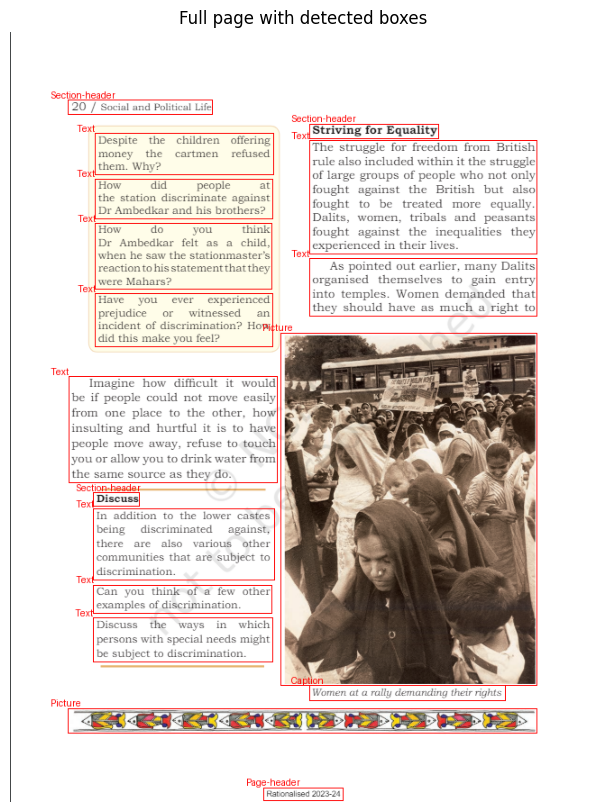

Text [94.08759307861328, 112.67927551269531, 292.0863342285156, 158.54493713378906] 0.7912276387214661


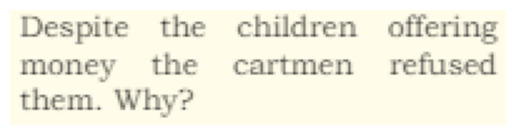

----
Text [332.1262512207031, 120.54322814941406, 584.0625, 246.75209045410156] 0.974174976348877


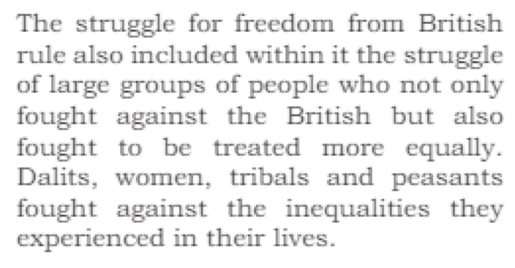

----
Text [94.0747299194336, 163.08692932128906, 291.0406494140625, 207.19000244140625] 0.7467000484466553


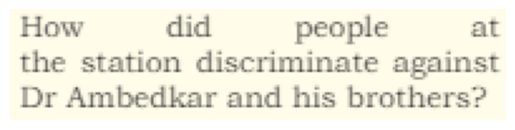

----
Text [94.59051513671875, 212.92721557617188, 290.79541015625, 285.7200012207031] 0.676749050617218


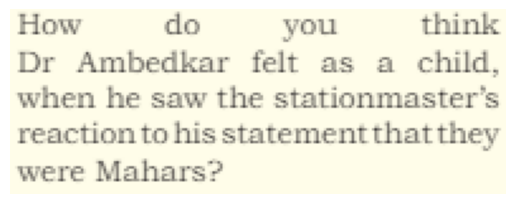

----
Text [332.3852233886719, 251.94802856445312, 584.167724609375, 315.6915283203125] 0.9526651501655579


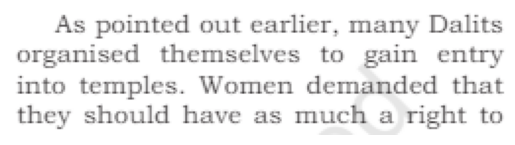

----
Text [94.71693420410156, 290.7782897949219, 291.98699951171875, 349.4700927734375] 0.8376380801200867


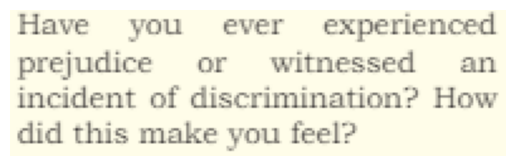

----
Text [65.04634094238281, 382.956298828125, 296.8056945800781, 500.3667297363281] 0.971107006072998


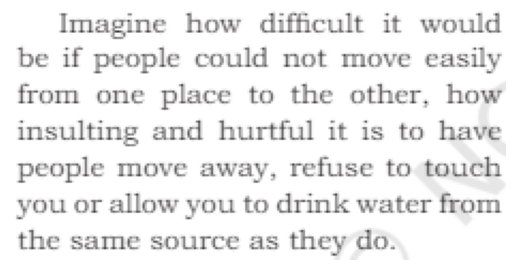

----
Text [92.69125366210938, 529.7723388671875, 293.0060119628906, 608.6044921875] 0.8653848171234131


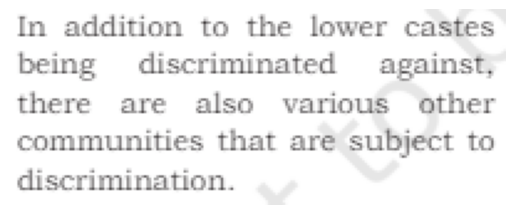

----
Text [92.83472442626953, 614.1206665039062, 290.7925720214844, 645.180908203125] 0.7834395170211792


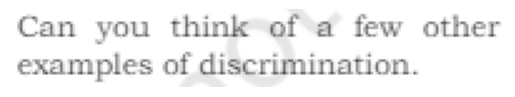

----
Text [92.33747863769531, 650.6906127929688, 291.3896179199219, 699.4176025390625] 0.7699803709983826


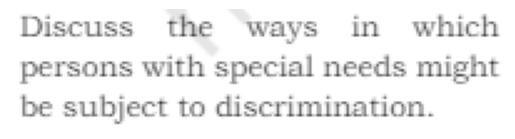

----
Picture [300.4553527832031, 334.48193359375, 584.8563232421875, 725.8092651367188] 0.9626560807228088


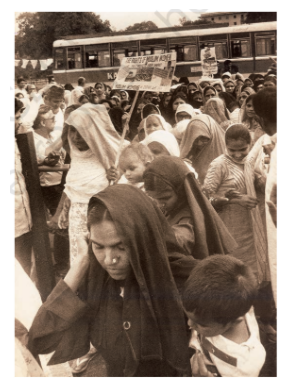

----
Picture [64.73655700683594, 751.3209228515625, 584.7588500976562, 778.9571533203125] 0.5007762908935547


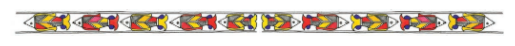

----
Section-header [64.85264587402344, 75.72174835205078, 224.86917114257812, 91.84431457519531] 0.30184295773506165


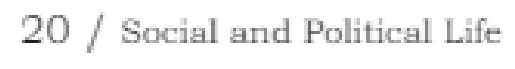

----
Section-header [332.302978515625, 102.40351104736328, 475.4624328613281, 118.54778289794922] 0.8534054756164551


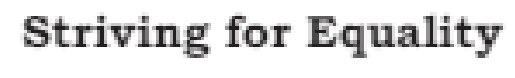

----
Section-header [92.64907836914062, 511.814697265625, 143.9576873779297, 526.9379272460938] 0.824130117893219


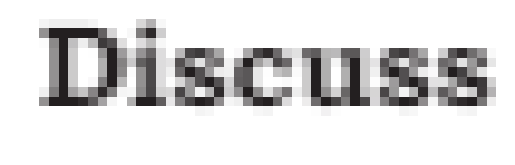

----
Caption [332.30084228515625, 725.9512939453125, 549.5217895507812, 742.3832397460938] 0.8007872104644775


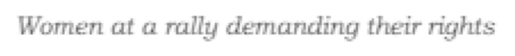

----
Page-header [281.6375427246094, 839.2086181640625, 369.1959228515625, 853.3876342773438] 0.43547993898391724


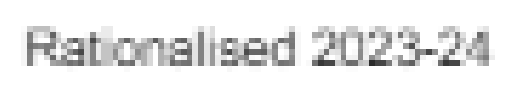

----


In [33]:
info = dla(image_path)

******************OCR**********************


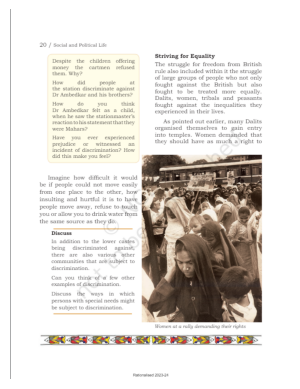

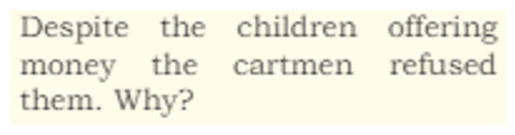

Despite the children offering
money the cartmen refused
them. Why?



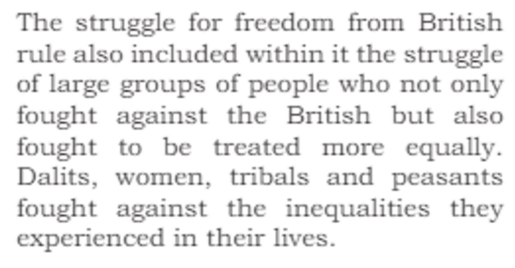

The struggle for freedom from British
rule also included within it the struggle
of large groups of people who not only
fought against the British but also
fought to be treated more equally.
Dalits, women, tribals and peasants
fought against the inequalities they
experienced in their lives.



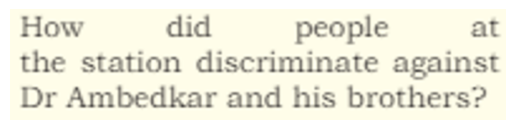

How did people at
the station discriminate against
Dr Ambedkar and his brothers?



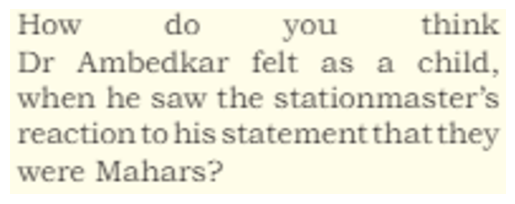

How do you think
Dr Ambedkar felt as a child,
when he saw the stationmaster’s
reaction to his statement that they
were Mahars?



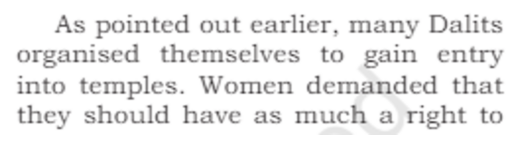

As pointed out earlier, many Dalits
organised themselves to gain entry
into temples. Women demanded that
they should have as much a right to



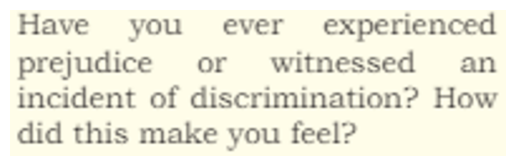

Have you ever experienced
prejudice or witnessed an
incident of discrimination? How
did this make you feel?



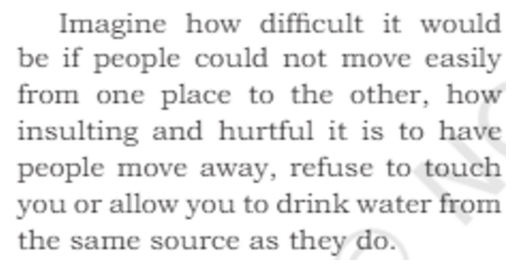

Imagine how difficult it would
be if people could not move easily
from one place to the other, how
insulting and hurtful it is to have
people move away, refuse to touch
you or allow you to drink water from
the same source as they do.



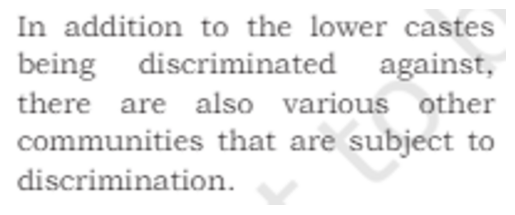

In addition to the lower castes
being discriminated against,
there are also various other
communities that are subject to
discrimination.



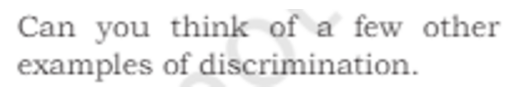

Can you think of a few other
examples of discrimination.



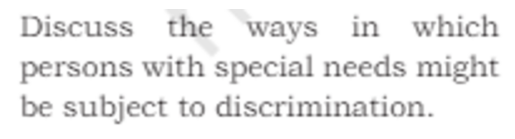

Discuss the ways in which
persons with special needs might
be subject to discrimination.



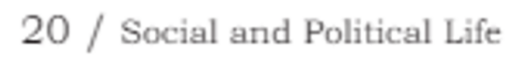

20 / Social and Political Life



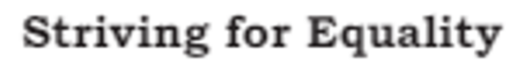

Striving for Equality



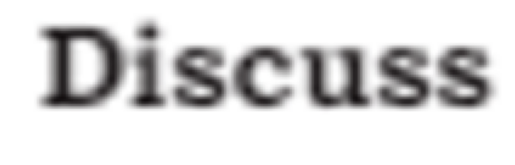

Discuss



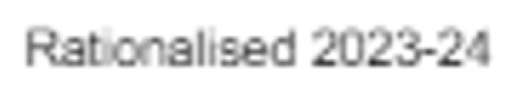

Rahonalised 2023-24

Lines:
_*Page-header:Rahonalised 2023-24 *_.
_*Section-header:20 / Social and Political Life *_.
_*Section-header:Striving for Equality *_.
Despite the children offering money the cartmen refused them. Why?
The struggle for freedom from British rule also included within it the struggle of large groups of people who not only fought against the British but also fought to be treated more equally. Dalits, women, tribals and peasants fought against the inequalities they experienced in their lives.
How did people at the station discriminate against Dr Ambedkar and his brothers?
How do you think Dr Ambedkar felt as a child, when he saw the stationmaster’s reaction to his statement that they were Mahars?
As pointed out earlier, many Dalits organised themselves to gain entry into temples. Women demanded that they should have as much a right to
Have you ever experienced prejudice or witnessed an incident of discrimination? How did this make you feel?
Imagine how difficult i

In [34]:
texts = ocr()

***********Captioning********************


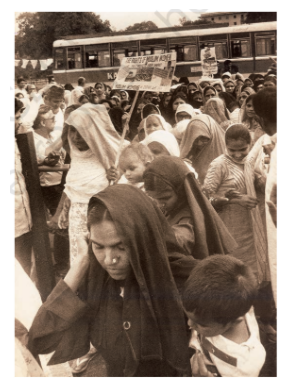

pic1
_*A picture: Women at a rally demanding their rights
*_.


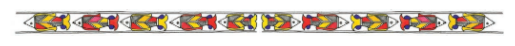

pic2
_*A picture of a close up of a colorful pattern on a white background*_.


In [26]:
captioning()

****************Imae Text Matching**********************


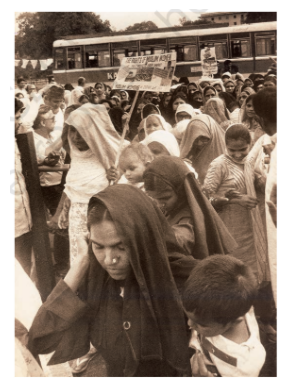

Associated text for pic1 : As pointed out earlier, many Dalits organised themselves to gain entry into temples.


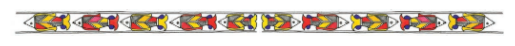

Associated text for pic2 : In addition to the lower castes being discriminated against, there are also various other communities that are subject to discrimination.


In [27]:
output_texts = itm(texts)

In [28]:
info

[{PosixPath('/content/Fig18.png'): {'Text': [([94.08759307861328,
      112.67927551269531,
      292.0863342285156,
      158.54493713378906],
     0.7912276387214661),
    ([332.1262512207031, 120.54322814941406, 584.0625, 246.75209045410156],
     0.974174976348877),
    ([94.0747299194336,
      163.08692932128906,
      291.0406494140625,
      207.19000244140625],
     0.7467000484466553),
    ([94.59051513671875,
      212.92721557617188,
      290.79541015625,
      285.7200012207031],
     0.676749050617218),
    ([332.3852233886719,
      251.94802856445312,
      584.167724609375,
      315.6915283203125],
     0.9526651501655579),
    ([94.71693420410156,
      290.7782897949219,
      291.98699951171875,
      349.4700927734375],
     0.8376380801200867),
    ([65.04634094238281,
      382.956298828125,
      296.8056945800781,
      500.3667297363281],
     0.971107006072998),
    ([92.69125366210938, 529.7723388671875, 293.0060119628906, 608.6044921875],
     0.865384817

In [29]:
output_texts

['_*Page-header:Rahonalised 2023-24 *_.',
 '_*Section-header:20 / Social and Political Life *_.',
 '_*Section-header:Striving for Equality *_.',
 'Despite the children offering money the cartmen refused them.',
 'Why?',
 'The struggle for freedom from British rule also included within it the struggle of large groups of people who not only fought against the British but also fought to be treated more equally.',
 'Dalits, women, tribals and peasants fought against the inequalities they experienced in their lives.',
 'How did people at the station discriminate against Dr Ambedkar and his brothers?',
 'How do you think Dr Ambedkar felt as a child, when he saw the stationmaster’s reaction to his statement that they were Mahars?',
 'As pointed out earlier, many Dalits organised themselves to gain entry into temples.',
 '_*A picture: Women at a rally demanding their rights\n\x0c*_.',
 'Women demanded that they should have as much a right to',
 'Have you ever experienced prejudice or witnessed

In [30]:

op = int(input("1)Tamil 2)Hindi 3)Telugu 4)Malayalam 5)Kannada 6)English:"))
if op == 1:
  tts(output_texts,"ta",-2,1,True)
elif op == 2:
  tts(output_texts,"hi",-2,1,True)
elif op == 3:
  tts(output_texts,"te",-2,1,True)
elif op == 4:
  tts(output_texts,"ml",-2,1,True)
elif op == 5:
  tts(output_texts,"kn",-2,1,True)
elif op == 6:
  tts(output_texts,"en",-2,1,True)

1)Tamil 2)Hindi 3)Telugu 4)Malayalam 5)Kannada 6)English:6


In [ ]:
Audio("combined_audio.wav")

In [ ]:
end_time = time.time()
elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} seconds")

Elapsed time: 791.3579061031342 seconds


In [ ]:
torch.cuda.empty_cache() #removed unused data from GPU memory to run next cycle

PubLaynet sample 3 english elapsed time: 167.7 seconds


---


PubLaynet sample english elapsed time: 106.56 seconds


---

PubLaynet sample Telugu elapsed time: 229.38 seconds


---

PubLaynet sample Tamil elapsed time: 244.95 seconds



---

PubLaynet sample 2 english elapsed time: 152.03 seconds


Parallel calling: (requires nearly 15 gb of T4 GPU, 8-9 gb of RAM and 60-65 gb disk)

PubLaynet sample english elapsed time: 57.6 seconds

PubLaynet sample Tamil elapsed time: 72.69 seconds

PubLaynet sample Hindi elapsed time: 79.65

PubLaynet sample 2 english elapsed time: 54.49 seconds

PubLaynet sample 3 english elapsed time: 33.78

PubLayne sample 3 kannada elapsed time: 72.46

In [ ]:
# prompt: kill session

import os
os.kill(os.getpid(), 9)


In [ ]:
import gtts
gtts.lang.tts_langs()

{'af': 'Afrikaans',
 'ar': 'Arabic',
 'bg': 'Bulgarian',
 'bn': 'Bengali',
 'bs': 'Bosnian',
 'ca': 'Catalan',
 'cs': 'Czech',
 'da': 'Danish',
 'de': 'German',
 'el': 'Greek',
 'en': 'English',
 'es': 'Spanish',
 'et': 'Estonian',
 'fi': 'Finnish',
 'fr': 'French',
 'gu': 'Gujarati',
 'hi': 'Hindi',
 'hr': 'Croatian',
 'hu': 'Hungarian',
 'id': 'Indonesian',
 'is': 'Icelandic',
 'it': 'Italian',
 'iw': 'Hebrew',
 'ja': 'Japanese',
 'jw': 'Javanese',
 'km': 'Khmer',
 'kn': 'Kannada',
 'ko': 'Korean',
 'la': 'Latin',
 'lv': 'Latvian',
 'ml': 'Malayalam',
 'mr': 'Marathi',
 'ms': 'Malay',
 'my': 'Myanmar (Burmese)',
 'ne': 'Nepali',
 'nl': 'Dutch',
 'no': 'Norwegian',
 'pl': 'Polish',
 'pt': 'Portuguese',
 'ro': 'Romanian',
 'ru': 'Russian',
 'si': 'Sinhala',
 'sk': 'Slovak',
 'sq': 'Albanian',
 'sr': 'Serbian',
 'su': 'Sundanese',
 'sv': 'Swedish',
 'sw': 'Swahili',
 'ta': 'Tamil',
 'te': 'Telugu',
 'th': 'Thai',
 'tl': 'Filipino',
 'tr': 'Turkish',
 'uk': 'Ukrainian',
 'ur': 'Urdu',
 '

In [ ]:
x = '''{'af': 'Afrikaans',
 'ar': 'Arabic',
 'bg': 'Bulgarian',
 'bn': 'Bengali',
 'bs': 'Bosnian',
 'ca': 'Catalan',
 'cs': 'Czech',
 'da': 'Danish',
 'de': 'German',
 'el': 'Greek',
 'en': 'English',
 'es': 'Spanish',
 'et': 'Estonian',
 'fi': 'Finnish',
 'fr': 'French',
 'gu': 'Gujarati',
 'hi': 'Hindi',
 'hr': 'Croatian',
 'hu': 'Hungarian',
 'id': 'Indonesian',
 'is': 'Icelandic',
 'it': 'Italian',
 'iw': 'Hebrew',
 'ja': 'Japanese',
 'jw': 'Javanese',
 'km': 'Khmer',
 'kn': 'Kannada',
 'ko': 'Korean',
 'la': 'Latin',
 'lv': 'Latvian',
 'ml': 'Malayalam',
 'mr': 'Marathi',
 'ms': 'Malay',
 'my': 'Myanmar (Burmese)',
 'ne': 'Nepali',
 'nl': 'Dutch',
 'no': 'Norwegian',
 'pl': 'Polish',
 'pt': 'Portuguese',
 'ro': 'Romanian',
 'ru': 'Russian',
 'si': 'Sinhala',
 'sk': 'Slovak',
 'sq': 'Albanian',
 'sr': 'Serbian',
 'su': 'Sundanese',
 'sv': 'Swedish',
 'sw': 'Swahili',
 'ta': 'Tamil',
 'te': 'Telugu',
 'th': 'Thai',
 'tl': 'Filipino',
 'tr': 'Turkish',
 'uk': 'Ukrainian',
 'ur': 'Urdu',
 'vi': 'Vietnamese',
 'zh-CN': 'Chinese (Simplified)',
 'zh-TW': 'Chinese (Mandarin/Taiwan)',
 'zh': 'Chinese (Mandarin)'}'''

import ast
len(list(ast.literal_eval(x).keys()))

59

##Pre-processing trials

In [ ]:
import matplotlib.pyplot as plt


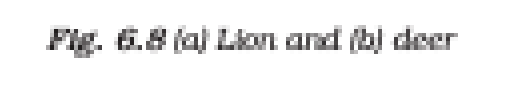

In [ ]:
img = Image.open('/content/sample2_cropped.png')
plt.imshow(img)
plt.axis('off')
plt.show()

In [ ]:
img.info.get('dpi')

(95.9866, 95.9866)

In [ ]:
img2 = Image.open('/content/sample2crop2.png')
print(img2.info.get('dpi'))

(95.9866, 95.9866)


In [ ]:
width = img.width
height = img.height


# Resize the cropped image to a larger size using high-quality interpolation
resize_factor = 8
new_width = width * resize_factor
new_height = height * resize_factor
resized_image = img.resize((new_width, new_height), Image.BICUBIC)

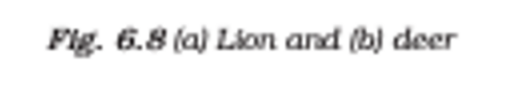

In [ ]:
plt.imshow(resized_image)
plt.axis('off')
plt.show()

In [ ]:
pytesseract.image_to_string(resized_image)

'Fig. 6.8 (a) Lion and (bj) deer\n\x0c'

In [ ]:
print(width,height)
print(resized_image.width,resized_image.height)

124 18


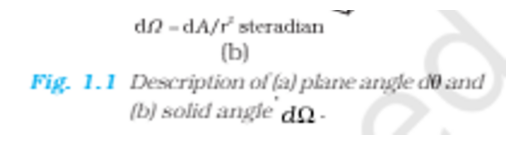

'dN -dA/r steradian\n(b)\nFig. 1.1 Description of fa) plane angle d@and\n(b) solid angle’ dg -\n\x0c'

In [ ]:
from PIL import Image

# Open the image with alpha channel
image = Image.open('/content/sample1_crop2.png')

# Convert the image to RGB mode (removes alpha channel)
image = image.convert("RGB")

# Convert the image to grayscale
# image = image.convert("L")

width = image.width
height = image.height

# Resize the cropped image to a larger size using high-quality interpolation
resize_factor = 4
new_width = width * resize_factor
new_height = height * resize_factor
resized_image = image.resize((new_width, new_height), Image.BICUBIC)

plt.imshow(resized_image)
plt.axis('off')
plt.show()
pytesseract.image_to_string(resized_image)

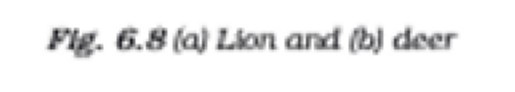

OCR Result:
Pig. 6.8 (a) Lion and (b) deer



In [ ]:
import cv2
import pytesseract
from PIL import Image

# Load the cropped image
img = cv2.imread('/content/sample2_cropped.png')

# Convert the image to grayscale
# img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_modified = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
# Apply Gaussian blur to reduce noise
# img_blurred = cv2.GaussianBlur(img_gray, (5, 5), 0)

# Perform adaptive thresholding to binarize the image
# img_thresholded = cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

# Perform OCR on the preprocessed image
text = pytesseract.image_to_string(img_modified)

plt.imshow(Image.fromarray(img_modified))
plt.axis('off')
plt.show()


# Display the OCR result
print("OCR Result:")
print(text)


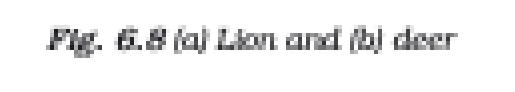

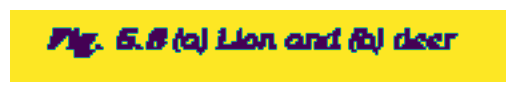

In [ ]:
img = cv2.imread('/content/sample2_cropped.png')
# Convert the image to grayscale
img_modified = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

img_modified = cv2.resize(img_modified, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
img_modified = cv2.threshold(img_modified, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
# img_modified = cv2.cvtColor(img_modified, cv2.COLOR_BGR2GRAY)
# kernel = np.ones((1, 1), np.uint8)
# img_modified = cv2.dilate(img_modified, kernel, iterations=1)
# img_modified = cv2.erode(img_modified, kernel, iterations=1)
# img_modified = cv2.threshold(cv2.medianBlur(img_modified, 3), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
plt.imshow(img)
plt.axis('off')
plt.show()
plt.imshow(img_modified)
plt.axis('off')
plt.show()
pytesseract.image_to_string(img_modified)

In [ ]:
!sudo apt-get install libtesseract-dev

In [ ]:
# %%capture
!pip install pytesseract
!sudo apt-get install tesseract-ocr
!sudo apt-get install libtesseract-dev

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  tesseract-ocr-eng tesseract-ocr-osd
The following NEW packages will be installed:
  tesseract-ocr tesseract-ocr-eng tesseract-ocr-osd
0 upgraded, 3 newly installed, 0 to remove and 45 not upgraded.
Need to get 4,816 kB of archives.
After this operation, 15.6 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr-eng all 1:4.00~git30-7274cfa-1.1 [1,591 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr-osd all 1:4.00~git30-7274cfa-1.1 [2,990 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr amd64 4.1.1-2.1build1 [236 kB]
Fetched 4,816 kB in 1s (4,798 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debc

In [ ]:
import pytesseract
pytesseract.pytesseract.tesseract_cmd = '/usr/bin/tesseract'

In [ ]:
pytesseract.image_to_string(Image.open('/content/UVcJV1leBEF-XR8FAA5VW1VQQ35cSQVX_UVcJV10IAxd-XR8FAA5RXQhWRS5RSVZS.jpg'))

"afe o7a yar\nah ah\nfaeRrit a ara aed\n\n%, aan ae ster ame ict) J\n\n: SO Caustic)\nwet oR Ua ax am: Pee CEs ket nc\n\ng\n\n \n\n \n\nTUS Wel Fae Yor & ‘SA Tet fers ARAM TT TR\nrena, ea? Sel ore ht aT oe TB aera at F\nwea g, ‘tt,\n\nFett aR A\nfart a aft tt\narendt ot arent set\nat e7'-aet afin A\nsae wife & arr i\nCra at Gea, STO AK Gee Usa ST Gh BAA\nFaas spare F eal Aha Sk ag Set SL\nfaa ar saa ean stare Sieefetar, fea Sk saver oft arrera\n281 ct a aad asta as IS Go Became see\n\nSa veel OA Pata gidselt Bl STATS I SA VK, SATS\n\nTT\n\n  \n\n \n\n \n\n \n\n \n\n \n\n \n\n \n\nae, GE aa sis Sa GE Gene @ saK St TUT Sl ae BK EH\n\n \n\nAlera ch aeriter sal RAR cht =a fre Maet Bale agar FH\n\naittteat Gah aor at gernr seat Gea at ara & are @, se\n\x0c"

In [ ]:
import cv2
import matplotlib.pyplot as plt

image1 = cv2.imread("/content/sample2_cropped.png")
# Load the image
image = cv2.imread("/content/sample2_cropped.png", cv2.IMREAD_GRAYSCALE)

# Thresholding
_, binary_image = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)

# Inversion (Optional)
binary_image = cv2.bitwise_not(binary_image)

# Noise Removal (Optional)
kernel = np.ones((3, 3), np.uint8)
binary_image = cv2.erode(binary_image, kernel, iterations=1)
binary_image = cv2.dilate(binary_image, kernel, iterations=1)


plt.imshow(image1)
plt.axis('off')
plt.show()
plt.imshow(binary_image)
plt.axis('off')
plt.show()
pytesseract.image_to_string(binary_image)